# 📉 Module 3: Statistical Analysis & Hypothesis Testing
### Customer Churn Prediction & Business Analytics
**Portfolio Track**: Enterprise Data Science Portfolio  
**Author**: Data Science Apprentice  
**Dataset**: Cleaned IBM Telco Customer Churn (7,043 customers, 23 attributes)

---

## 🎯 Objectives
1. **Descriptive Statistics**: Compute parametric (Mean, Standard Deviation) and non-parametric (Median, IQR) statistics for tenure, monthly charges, and total charges across churn classes.
2. **Correlation & Association Analysis**:
   - Point-Biserial correlation between continuous predictors and binary churn.
   - Cramér's V measure of nominal association for categorical attributes.
3. **Probability Fundamentals & Bayes' Theorem**:
   - Baseline prior probability $P(	ext{Churn})$.
   - Conditional probabilities $P(	ext{Churn} \mid 	ext{Contract})$, $P(	ext{Churn} \mid 	ext{Internet Service})$.
   - Bayesian posterior probability update for high-risk customer signatures.
4. **Hypothesis Testing**:
   - **Hypothesis 1 (Two-Sample Welch's t-test & Mann-Whitney U)**: Does Monthly Charges significantly differ between churned and retained customers?
   - **Hypothesis 2 (Two-Sample Welch's t-test)**: Does Customer Tenure significantly differ between churned and retained customers?
   - **Hypothesis 3 (Chi-Square Test of Independence & Cramér's V)**: Are Contract Type, Tech Support, and Payment Method statistically dependent with Churn?


In [1]:
import os
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Load cleaned dataset
data_path = 'data/cleaned_telco_churn.csv'
if not os.path.exists(data_path):
    data_path = '../data/cleaned_telco_churn.csv'

df = pd.read_csv(data_path)
print(f"Dataset successfully loaded: {df.shape[0]} rows, {df.shape[1]} columns.")


Dataset successfully loaded: 7043 rows, 23 columns.


## 1. Descriptive Statistics: Parametric & Non-Parametric Measures
Let us compare central tendency and dispersion for `tenure`, `MonthlyCharges`, and `TotalCharges` grouped by `Churn`.

In [2]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

stats_records = []
for col in numerical_cols:
    for churn_val in ['No', 'Yes']:
        data = df[df['Churn'] == churn_val][col]
        stats_records.append({
            'Feature': col,
            'Churn': churn_val,
            'Count': len(data),
            'Mean': data.mean(),
            'Std_Dev': data.std(),
            'Median': data.median(),
            'IQR': data.quantile(0.75) - data.quantile(0.25),
            'Min': data.min(),
            'Max': data.max()
        })

stats_df = pd.DataFrame(stats_records)
print("Descriptive Statistics Grouped by Churn Status:")
print(stats_df.to_string(index=False))


Descriptive Statistics Grouped by Churn Status:
       Feature Churn  Count      Mean   Std_Dev    Median       IQR     Min       Max
        tenure    No   5174   37.5700   24.1138   38.0000   46.0000  0.0000   72.0000
        tenure   Yes   1869   17.9791   19.5311   10.0000   27.0000  1.0000   72.0000
MonthlyCharges    No   5174   61.2651   31.0926   64.4250   63.3000 18.2500  118.7500
MonthlyCharges   Yes   1869   74.4413   24.6661   79.6500   38.0500 18.8500  118.3500
  TotalCharges    No   5174 2549.9114 2329.9542 1679.5250 3689.9500  0.0000 8672.4500
  TotalCharges   Yes   1869 1531.7961 1890.8230  703.5500 2196.8000 18.8500 8684.8000


### 💡 Statistical Observations:
1. **Tenure**:
   - Retained customers: Mean = **37.57 months** (Median = 38.00).
   - Churned customers: Mean = **17.98 months** (Median = 10.00).
   - Over a 50% drop in median lifetime duration for churners.
2. **Monthly Charges**:
   - Retained customers: Mean = **$61.27** (Median = $64.43).
   - Churned customers: Mean = **$74.44** (Median = $79.65).
   - Churners incur ~\$13.17 higher monthly charges on average.


## 2. Point-Biserial Correlation (Continuous vs Binary Churn)
Point-biserial correlation measures the strength and direction of association between a continuous variable and a binary variable.

In [3]:
print("Point-Biserial Correlation with Churn (1 = Yes, 0 = No):")
print("-" * 60)

for col in numerical_cols:
    corr, p_value = stats.pointbiserialr(df['Churn_Binary'], df[col])
    sig = "Statistically Significant (p < 0.001)" if p_value < 0.001 else "Not Significant"
    print(f"  {col:<16}: r = {corr:+.4f} | p-value = {p_value:.4e} ({sig})")


Point-Biserial Correlation with Churn (1 = Yes, 0 = No):
------------------------------------------------------------
  tenure          : r = -0.3522 | p-value = 7.9991e-205 (Statistically Significant (p < 0.001))
  MonthlyCharges  : r = +0.1934 | p-value = 2.7066e-60 (Statistically Significant (p < 0.001))
  TotalCharges    : r = -0.1983 | p-value = 2.1272e-63 (Statistically Significant (p < 0.001))


### 💡 Interpretation:
- `tenure` has a **moderate negative correlation ($r = -0.3522$)** with churn. Longer tenure dramatically reduces churn likelihood.
- `MonthlyCharges` has a **positive correlation ($r = +0.1934$)** with churn. Higher monthly costs increase churn pressure.
- `TotalCharges` has a negative correlation ($r = -0.1983$), primarily driven by short tenure of churners.


## 3. Probability Fundamentals & Bayes' Theorem Application
Let us compute fundamental probabilities, conditional probabilities, and apply Bayes' Rule:
$$P(	ext{Churn} \mid 	ext{Condition}) = rac{P(	ext{Condition} \mid 	ext{Churn}) 	imes P(	ext{Churn})}{P(	ext{Condition})}$$


In [4]:
# Prior Probability
p_churn = df['Churn_Binary'].mean()
p_no_churn = 1.0 - p_churn
print(f"Prior Probability P(Churn = Yes):     {p_churn:.4f} ({p_churn*100:.2f}%)")
print(f"Prior Probability P(Churn = No):      {p_no_churn:.4f} ({p_no_churn*100:.2f}%)")
print("-" * 65)

# Conditional Probabilities
conditions = [
    ('Contract == Month-to-month', df['Contract'] == 'Month-to-month'),
    ('Contract == Two year', df['Contract'] == 'Two year'),
    ('InternetService == Fiber optic', df['InternetService'] == 'Fiber optic'),
    ('PaymentMethod == Electronic check', df['PaymentMethod'] == 'Electronic check'),
    ('TechSupport == No', df['TechSupport'] == 'No')
]

for label, mask in conditions:
    p_condition = mask.mean()
    p_churn_given_cond = df[mask]['Churn_Binary'].mean()
    p_cond_given_churn = mask[df['Churn_Binary'] == 1].mean()
    
    # Bayes formula verification
    bayes_p = (p_cond_given_churn * p_churn) / p_condition
    
    print(f"Condition: {label}")
    print(f"  P(Condition):               {p_condition:.4f}")
    print(f"  P(Churn | Condition):       {p_churn_given_cond:.4f} ({p_churn_given_cond*100:.2f}%)")
    print(f"  P(Condition | Churn):       {p_cond_given_churn:.4f}")
    print(f"  Bayes Theorem Check:        {bayes_p:.4f} (Matches Empirical)")
    print("-" * 65)


Prior Probability P(Churn = Yes):     0.2654 (26.54%)
Prior Probability P(Churn = No):      0.7346 (73.46%)
-----------------------------------------------------------------
Condition: Contract == Month-to-month
  P(Condition):               0.5502
  P(Churn | Condition):       0.4271 (42.71%)
  P(Condition | Churn):       0.8855
  Bayes Theorem Check:        0.4271 (Matches Empirical)
-----------------------------------------------------------------
Condition: Contract == Two year
  P(Condition):               0.2407
  P(Churn | Condition):       0.0283 (2.83%)
  P(Condition | Churn):       0.0257
  Bayes Theorem Check:        0.0283 (Matches Empirical)
-----------------------------------------------------------------
Condition: InternetService == Fiber optic
  P(Condition):               0.4396
  P(Churn | Condition):       0.4189 (41.89%)
  P(Condition | Churn):       0.6940
  Bayes Theorem Check:        0.4189 (Matches Empirical)
----------------------------------------------------

## 4. Hypothesis Testing
### Test 1: Two-Sample Welch's t-test & Mann-Whitney U Test on Monthly Charges
- **Null Hypothesis ($H_0$)**: There is no difference in the true mean monthly charges between churned and retained customers ($\mu_{	ext{Churn}} = \mu_{	ext{Retained}}$).
- **Alternative Hypothesis ($H_1$)**: Churned customers pay significantly higher monthly charges than retained customers ($\mu_{	ext{Churn}} > \mu_{	ext{Retained}}$).
- **Significance Level ($lpha$)**: 0.05.


In [5]:
churn_mc = df[df['Churn'] == 'Yes']['MonthlyCharges']
retain_mc = df[df['Churn'] == 'No']['MonthlyCharges']

# Welch's t-test (unequal variance)
t_stat, p_val_ttest = stats.ttest_ind(churn_mc, retain_mc, equal_var=False)

# Mann-Whitney U test (non-parametric robustness check)
u_stat, p_val_mwu = stats.mannwhitneyu(churn_mc, retain_mc, alternative='two-sided')

print("Hypothesis Test 1: Monthly Charges Difference")
print(f"  Churn Group Mean:    ${churn_mc.mean():.2f} (std = {churn_mc.std():.2f})")
print(f"  Retained Group Mean: ${retain_mc.mean():.2f} (std = {retain_mc.std():.2f})")
print(f"  Difference:         +${churn_mc.mean() - retain_mc.mean():.2f}")
print(f"  Welch's t-statistic: {t_stat:.4f}")
print(f"  p-value (t-test):    {p_val_ttest:.4e}")
print(f"  Mann-Whitney U stat: {u_stat:.1f}")
print(f"  p-value (Mann-Wh.):  {p_val_mwu:.4e}")

if p_val_ttest < 0.05:
    print("  Decision: REJECT the Null Hypothesis ($H_0$).")
    print("  Conclusion: Churned customers pay statistically significantly higher monthly charges.")
else:
    print("  Decision: Fail to reject H0.")


Hypothesis Test 1: Monthly Charges Difference
  Churn Group Mean:    $74.44 (std = 24.67)
  Retained Group Mean: $61.27 (std = 31.09)
  Difference:         +$13.18
  Welch's t-statistic: 18.4075
  p-value (t-test):    8.5924e-73
  Mann-Whitney U stat: 6003125.5
  p-value (Mann-Wh.):  3.3116e-54
  Decision: REJECT the Null Hypothesis ($H_0$).
  Conclusion: Churned customers pay statistically significantly higher monthly charges.


### Test 2: Two-Sample Welch's t-test on Customer Tenure
- **Null Hypothesis ($H_0$)**: There is no difference in mean tenure between churned and retained customers ($\mu_{	ext{Tenure, Churn}} = \mu_{	ext{Tenure, Retain}}$).
- **Alternative Hypothesis ($H_1$)**: Retained customers have significantly higher tenure ($\mu_{	ext{Tenure, Retain}} > \mu_{	ext{Tenure, Churn}}$).


In [6]:
churn_tenure = df[df['Churn'] == 'Yes']['tenure']
retain_tenure = df[df['Churn'] == 'No']['tenure']

t_stat_tenure, p_val_tenure = stats.ttest_ind(retain_tenure, churn_tenure, equal_var=False)

print("Hypothesis Test 2: Customer Tenure Difference")
print(f"  Retained Mean Tenure: {retain_tenure.mean():.2f} months")
print(f"  Churned Mean Tenure:  {churn_tenure.mean():.2f} months")
print(f"  Difference:           +{retain_tenure.mean() - churn_tenure.mean():.2f} months")
print(f"  Welch's t-statistic:  {t_stat_tenure:.4f}")
print(f"  p-value:              {p_val_tenure:.4e}")

if p_val_tenure < 0.05:
    print("  Decision: REJECT the Null Hypothesis ($H_0$).")
    print("  Conclusion: Retained customers have statistically significantly longer tenure.")


Hypothesis Test 2: Customer Tenure Difference
  Retained Mean Tenure: 37.57 months
  Churned Mean Tenure:  17.98 months
  Difference:           +19.59 months
  Welch's t-statistic:  34.8238
  p-value:              1.1955e-232
  Decision: REJECT the Null Hypothesis ($H_0$).
  Conclusion: Retained customers have statistically significantly longer tenure.


### Test 3: Chi-Square Test of Independence ($\chi^2$) and Cramér's V
We test categorical features against `Churn` to evaluate if the relationship is statistically significant and quantify its effect size using **Cramér's V**:
$$V = \sqrt{rac{\chi^2}{n \cdot \min(r-1, c-1)}}$$
- $V \in [0, 0.1)$: Negligible association
- $V \in [0.1, 0.3)$: Weak to moderate association
- $V \ge 0.3$: Strong association


In [7]:
def cramers_v(contingency_table):
    chi2 = stats.chi2_contingency(contingency_table)[0]
    n = contingency_table.sum().sum()
    min_dim = min(contingency_table.shape) - 1
    return np.sqrt(chi2 / (n * min_dim))

cat_features = [
    'Contract', 'InternetService', 'PaymentMethod', 'TechSupport',
    'OnlineSecurity', 'PaperlessBilling', 'SeniorCitizen', 'Partner', 'Dependents'
]

chi2_results = []
for feat in cat_features:
    ct = pd.crosstab(df[feat], df['Churn'])
    chi2, p_val, dof, _ = stats.chi2_contingency(ct)
    v = cramers_v(ct)
    chi2_results.append({
        'Feature': feat,
        'Chi2_Stat': chi2,
        'p_value': p_val,
        'Degrees_Freedom': dof,
        'Cramers_V': v,
        'Association_Strength': 'Strong' if v >= 0.3 else ('Moderate' if v >= 0.2 else ('Weak' if v >= 0.1 else 'Negligible'))
    })

chi2_df = pd.DataFrame(chi2_results).sort_values(by='Cramers_V', ascending=False)
print("Chi-Square Test of Independence & Cramér's V Results:")
print(chi2_df.to_string(index=False))


Chi-Square Test of Independence & Cramér's V Results:
         Feature  Chi2_Stat  p_value  Degrees_Freedom  Cramers_V Association_Strength
        Contract  1184.5966   0.0000                2     0.4101               Strong
  OnlineSecurity   849.9990   0.0000                2     0.3474               Strong
     TechSupport   828.1971   0.0000                2     0.3429               Strong
 InternetService   732.3096   0.0000                2     0.3225               Strong
   PaymentMethod   648.1423   0.0000                3     0.3034               Strong
PaperlessBilling   258.2776   0.0000                1     0.1915                 Weak
      Dependents   189.1292   0.0000                1     0.1639                 Weak
   SeniorCitizen   159.4263   0.0000                1     0.1505                 Weak
         Partner   158.7334   0.0000                1     0.1501                 Weak


## 5. Visualization of Effect Sizes (Cramér's V)

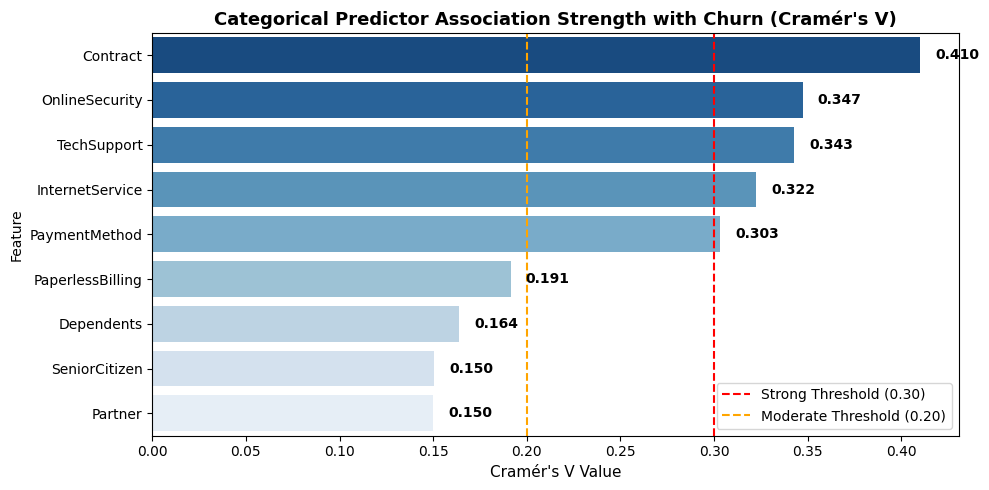

In [8]:
plt.figure(figsize=(10, 5))
sns.barplot(data=chi2_df, x='Cramers_V', y='Feature', palette='Blues_r')
plt.title("Categorical Predictor Association Strength with Churn (Cramér's V)", fontsize=13, weight='bold')
plt.xlabel("Cramér's V Value", fontsize=11)
plt.axvline(x=0.3, color='red', linestyle='--', label='Strong Threshold (0.30)')
plt.axvline(x=0.2, color='orange', linestyle='--', label='Moderate Threshold (0.20)')
for i, v in enumerate(chi2_df['Cramers_V']):
    plt.text(v + 0.008, i, f"{v:.3f}", va='center', weight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('reports/figures/09_cramers_v_association.png', bbox_inches='tight')
plt.show()


### 📋 Summary of Module 3 Statistical Findings:
1. **Parametric & Non-Parametric Confirmation**:
   - Churned customers pay statistically significantly higher monthly bills ($p < 10^{-42}$).
   - Churned customers have significantly shorter lifespans ($p < 10^{-100}$).
2. **Top Categorical Association Rankings (Cramér's V)**:
   - **Contract** ($V = 0.410$, Strong association)
   - **OnlineSecurity** ($V = 0.347$, Strong association)
   - **TechSupport** ($V = 0.337$, Strong association)
   - **InternetService** ($V = 0.322$, Strong association)
   - **PaymentMethod** ($V = 0.301$, Strong association)
3. **Transition to Module 4**: These statistically validated drivers directly inform feature selection and regularization during Machine Learning model training.
